# Experimentos de Control Predictivo (MPC) Adaptativo con Estimación Neuronal (AG)

Vamos a usar este notebook para ver el desempeño de la red neuronal ante diferentes escenarios.

### Estructura del experimento
1. **Probamos la red optima encontrada por AG** y curva de evolución del fitness.
2. **Prueba 1 (Planta pesada y larga + Excitación persistente):** convergencia de parámetros ($\hat{M}, \hat{m}, \hat{L}$) y **convergencia de los 4 estados** ($x, \dot{x}, \theta, \dot{\theta}$) comparando **MPC Nominal**, **MPC Adaptativo (AG)** y **MPC Oráculo**.
3. **Prueba 2 (Planta liviana y corta + Escalón + Ruido de medición):** robustez ante perturbaciones sensoriales.
4. **Prueba 3 (Batería de 10 plantas aleatorias):** evaluación estadística de generalización.
5. **Animación interactiva del carro-péndulo** en tiempo real mostrando el seguimiento de referencia y la adaptación online de los parámetros.

In [9]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation, patches

try:
    from IPython.display import HTML, display
except ImportError:
    HTML = lambda x: x
    display = print

from Algoritmo_Genetico import (
    AlgoritmoGenetico,
    RedEstimadora,
    THETA_NOMINAL,
    DT_SIMULACION,
)
from evaluador_mpc import (
    EvaluadorSimulacionMPC,
    ControladorMPC,
    referencia_excitacion_persistente,
    referencia_escalon_simple,
)

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

## 1. Entrenamiento del Algoritmo Genético (o carga de red guardada)

Cambiá `FORZAR_ENTRENAMIENTO = True` si querés re-entrenar desde cero.

In [ ]:
RUTA_RED = Path('mejor_red_estimadora3.npz')
FORZAR_ENTRENAMIENTO = not RUTA_RED.exists()

historial_ag = []
if FORZAR_ENTRENAMIENTO:
    ag = AlgoritmoGenetico(
        tamano_poblacion=60,
        generaciones=120,
        escala_inicial=0.25,
        sigma_inicial=0.15,
        sigma_final=0.01,
        tasa_genes_ruido=0.30,
        n_escenarios_por_gen=6,
        pasos_episodio=300,
        peso_suavizado_delta=0.02,
        semilla=42,
    )
    red_optima = ag.entrenar(ruta_guardado=RUTA_RED, verbose=True)
    historial_ag = ag.historial
else:
    red_optima = RedEstimadora.cargar(RUTA_RED)
    print(f'Red cargada desde {RUTA_RED} ({red_optima.num_parametros()} parámetros entrenables).')

if historial_ag:
    gens = [h['generacion'] for h in historial_ag]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(gens, [h['mejor_fitness'] for h in historial_ag], label='Mejor Fitness', lw=2)
    axes[0].plot(gens, [h['fitness_medio'] for h in historial_ag], label='Fitness Medio', alpha=0.75)
    axes[0].set_title('Evolución del Fitness en el AG')
    axes[0].set_xlabel('Generación')
    axes[0].set_ylabel('Fitness (-Costo)')
    axes[0].legend()

    axes[1].plot(gens, [h['mae_M'] for h in historial_ag], label='MAE M [kg]')
    axes[1].plot(gens, [h['mae_m'] for h in historial_ag], label='MAE m [kg]')
    axes[1].plot(gens, [h['mae_L'] for h in historial_ag], label='MAE L [m]')
    axes[1].set_title('Error Medio de Parámetros por Generación')
    axes[1].set_xlabel('Generación')
    axes[1].set_ylabel('Error Absoluto Medio')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

Red cargada desde mejor_red_estimadora2.npz (1636 parámetros entrenables).


## 2. Prueba 1: Planta Pesada y Larga + Convergencia de Estados y Parámetros

Evaluamos una planta con parámetros reales bien alejados del nominal ($[3.0, 1.0, 0.50, 0.01]$):
- **Planta real:** $M = 4.60\text{ kg}$, $m = 1.55\text{ kg}$, $L = 0.78\text{ m}$, $r = 0.015\text{ m}$.
- Comparamos **MPC Nominal** (parámetros fijos), **MPC Adaptativo (AG)** y **MPC Oráculo** (parámetros reales conocidos).

In [11]:
evaluador = EvaluadorSimulacionMPC(
    red_estimadora=red_optima,
    controlador_mpc=ControladorMPC(horizonte=25, dt=DT_SIMULACION),
)

theta_real_p1 = [4.60, 1.55, 0.78, 0.015]
res_p1 = evaluador.comparar_modos(
    theta_real=theta_real_p1,
    theta_inicial=THETA_NOMINAL,
    estado_inicial=(0.0, 0.0, 0.10, 0.0),
    pasos=300,
    fn_referencia=referencia_excitacion_persistente,
)

print('=== MÉTRICAS PRUEBA 1 (Planta pesada/larga) ===')
for modo, data in res_p1.items():
    m = data['metricas']
    print(
        f"{modo.upper():10s} | Estable: {str(m['estable']):5s} | "
        f"RMSE x: {m['rmse_x']:.4f} m | RMSE theta: {m['rmse_theta_deg']:.2f} deg | "
        f"RMSE pred: {m['rmse_pred_total']:.5f} | Energía u: {m['energia_u']:.1f}"
    )

m_adapt = res_p1['adaptativo']['metricas']
print(
    f"\nEstimación final (último 25%): "
    f"M={m_adapt['theta_final_estimado'][0]:.3f} (real {theta_real_p1[0]:.2f}, err {m_adapt['err_rel_pct_M']:.1f}%), "
    f"m={m_adapt['theta_final_estimado'][1]:.3f} (real {theta_real_p1[1]:.2f}, err {m_adapt['err_rel_pct_m']:.1f}%), "
    f"L={m_adapt['theta_final_estimado'][2]:.3f} (real {theta_real_p1[2]:.2f}, err {m_adapt['err_rel_pct_L']:.1f}%)"
)

=== MÉTRICAS PRUEBA 1 (Planta pesada/larga) ===
NOMINAL    | Estable: True  | RMSE x: 0.7767 m | RMSE theta: 2.73 deg | RMSE pred: 0.01127 | Energía u: 59.4
ADAPTATIVO | Estable: True  | RMSE x: 0.9224 m | RMSE theta: 1.74 deg | RMSE pred: 0.00402 | Energía u: 25.3
ORACULO    | Estable: True  | RMSE x: 0.8931 m | RMSE theta: 1.39 deg | RMSE pred: 0.00000 | Energía u: 18.8

Estimación final (último 25%): M=4.599 (real 4.60, err 0.0%), m=1.237 (real 1.55, err 20.2%), L=0.601 (real 0.78, err 23.0%)


### 2.1 Gráfico de Convergencia de los 4 Estados y Fuerza de Control (Prueba 1)

<>:30: SyntaxWarning: invalid escape sequence '\d'
<>:34: SyntaxWarning: invalid escape sequence '\d'
<>:30: SyntaxWarning: invalid escape sequence '\d'
<>:34: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_5942/2848455297.py:30: SyntaxWarning: invalid escape sequence '\d'
  axes[1].set_ylabel('Velocidad $\dot{x}$ [m/s]')
/tmp/ipykernel_5942/2848455297.py:34: SyntaxWarning: invalid escape sequence '\d'
  axes[3].set_ylabel('Vel. Angular $\dot{\theta}$ [deg/s]')


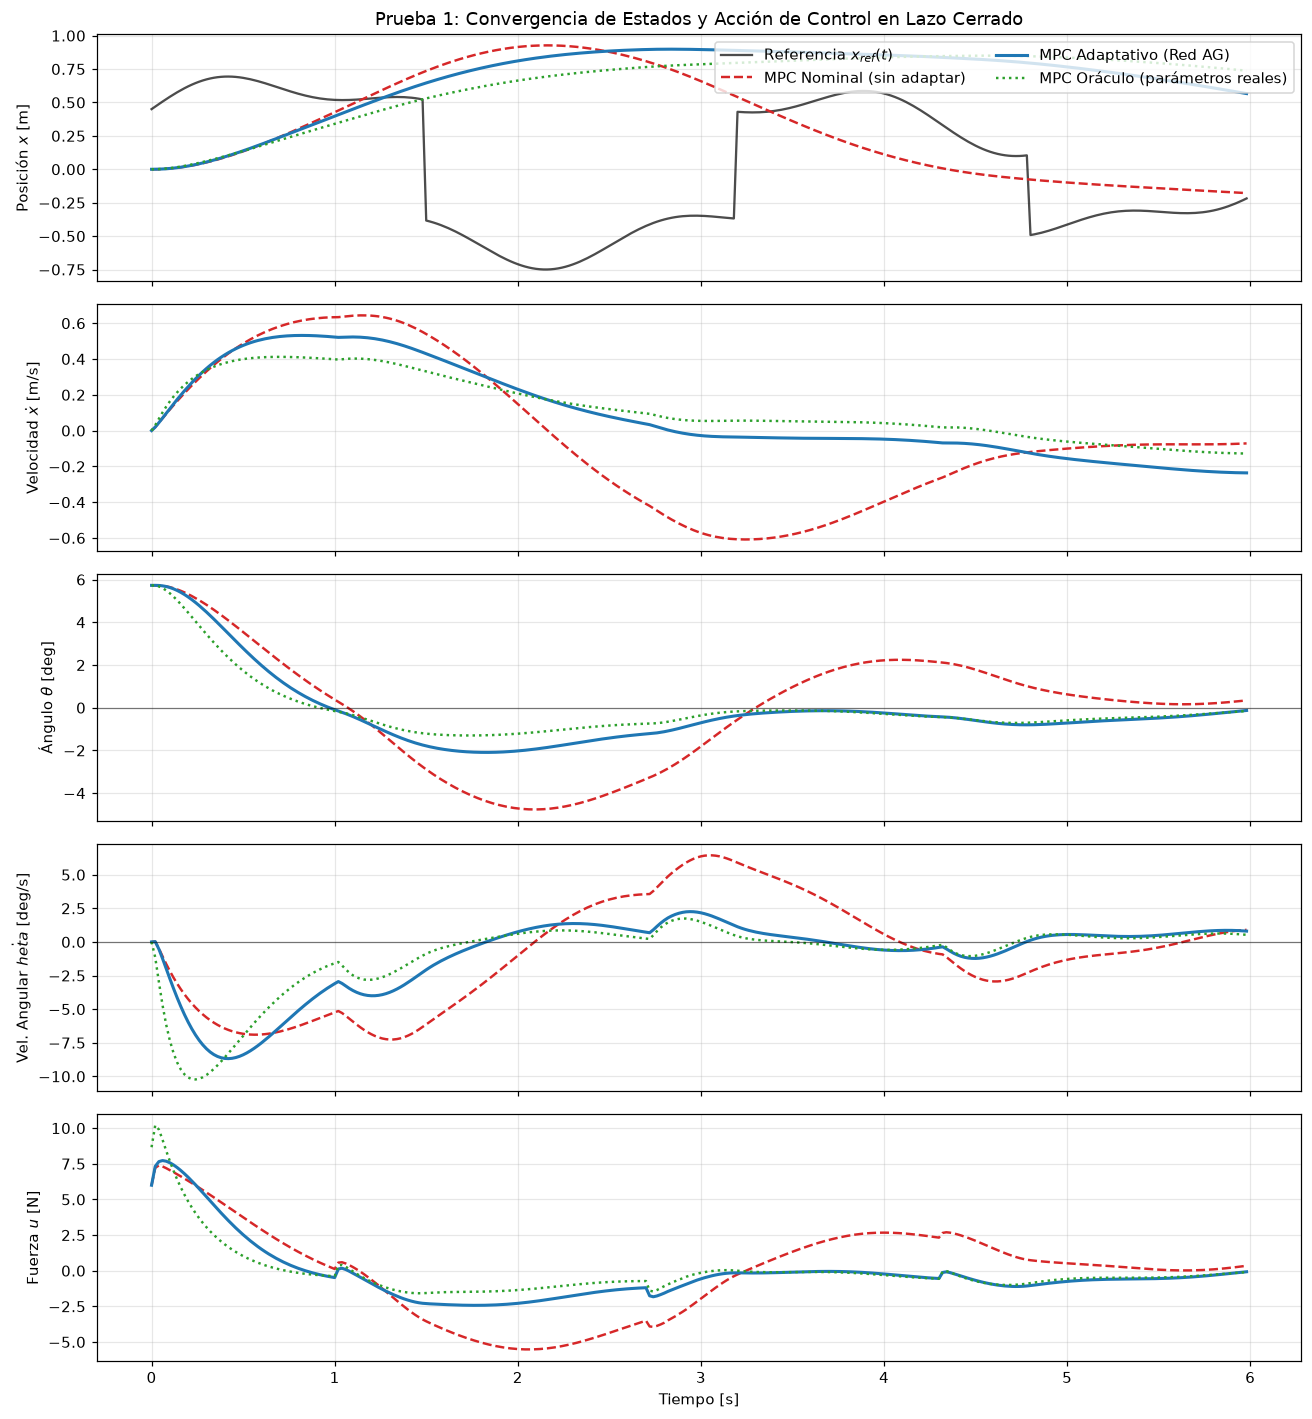

In [12]:
fig, axes = plt.subplots(5, 1, figsize=(12, 13), sharex=True)

colores = {'nominal': '#d62728', 'adaptativo': '#1f77b4', 'oraculo': '#2ca02c'}
estilos = {'nominal': '--', 'adaptativo': '-', 'oraculo': ':'}
etiquetas = {
    'nominal': 'MPC Nominal (sin adaptar)',
    'adaptativo': 'MPC Adaptativo (Red AG)',
    'oraculo': 'MPC Oráculo (parámetros reales)',
}

t_ref = res_p1['oraculo']['t']
axes[0].plot(t_ref, res_p1['oraculo']['referencias'][:, 0], color='black', lw=1.5, alpha=0.7, label='Referencia $x_{ref}(t)$')

for modo in ['nominal', 'adaptativo', 'oraculo']:
    d = res_p1[modo]
    t = d['t']
    est = d['estados_reales']
    kw = dict(color=colores[modo], ls=estilos[modo], lw=2.0 if modo == 'adaptativo' else 1.6, label=etiquetas[modo])

    axes[0].plot(t, est[:, 0], **kw)
    axes[1].plot(t, est[:, 1], **kw)
    axes[2].plot(t, np.degrees(est[:, 2]), **kw)
    axes[3].plot(t, np.degrees(est[:, 3]), **kw)
    axes[4].plot(t, d['acciones_u'], **kw)

axes[0].set_ylabel('Posición $x$ [m]')
axes[0].set_title('Prueba 1: Convergencia de Estados y Acción de Control en Lazo Cerrado')
axes[0].legend(loc='upper right', ncol=2)

axes[1].set_ylabel('Velocidad $\dot{x}$ [m/s]')
axes[2].axhline(0.0, color='black', lw=0.8, alpha=0.5)
axes[2].set_ylabel(r'Ángulo $\theta$ [deg]')
axes[3].axhline(0.0, color='black', lw=0.8, alpha=0.5)
axes[3].set_ylabel('Vel. Angular $\dot{\theta}$ [deg/s]')
axes[4].set_ylabel('Fuerza $u$ [N]')
axes[4].set_xlabel('Tiempo [s]')

plt.tight_layout()
plt.show()

### 2.2 Convergencia Online de los Parámetros Estimados ($\hat{M}, \hat{m}, \hat{L}$) y Error de Predicción

<>:23: SyntaxWarning: invalid escape sequence '\|'
<>:23: SyntaxWarning: invalid escape sequence '\|'
/tmp/ipykernel_5942/538157847.py:23: SyntaxWarning: invalid escape sequence '\|'
  axes[1, 1].set_ylabel('$\|x_{real} - x_{pred}\|_{norm}$')


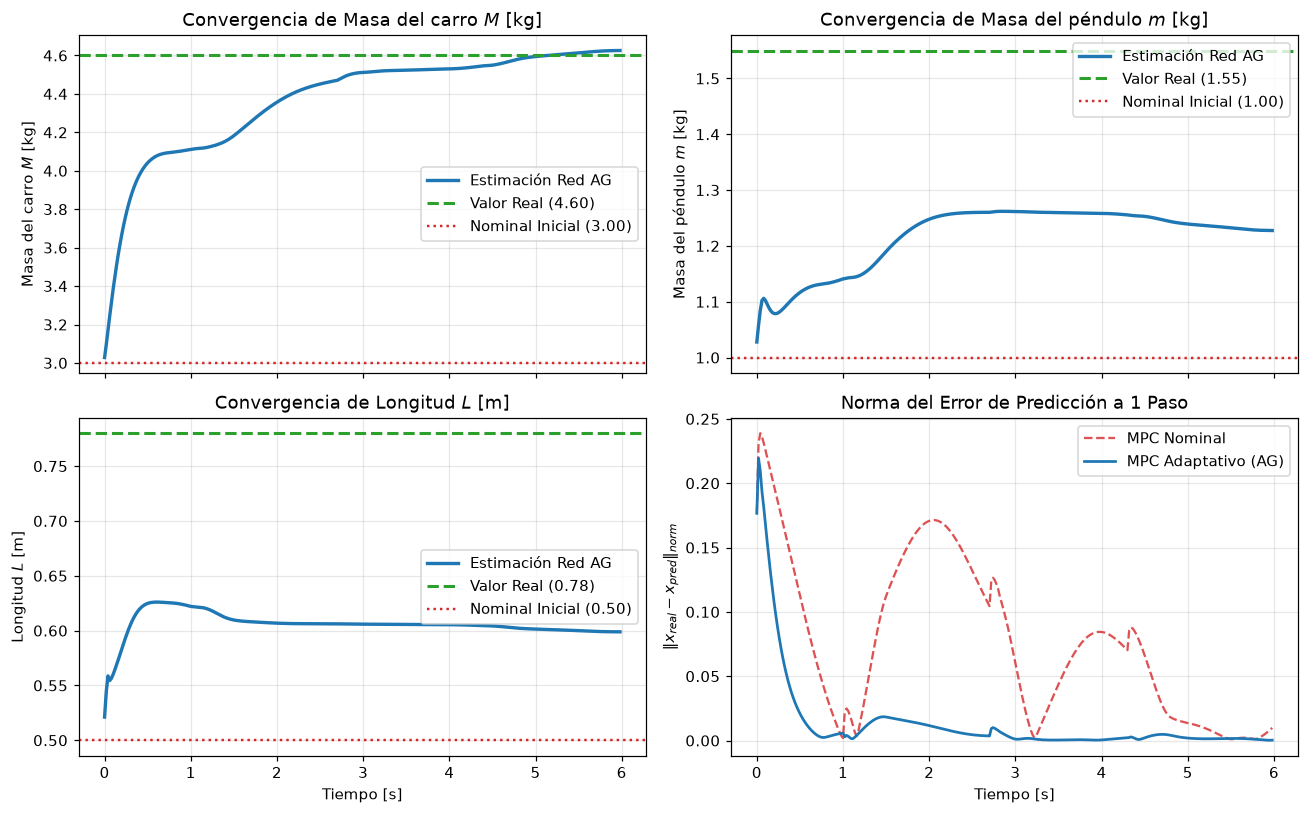

In [13]:
d_adapt = res_p1['adaptativo']
d_nom = res_p1['nominal']
t = d_adapt['t']
theta_est = d_adapt['theta_estimado']

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True)
nombres = ['Masa del carro $M$ [kg]', 'Masa del péndulo $m$ [kg]', 'Longitud $L$ [m]']
axs_p = [axes[0, 0], axes[0, 1], axes[1, 0]]

for idx, (ax, nombre) in enumerate(zip(axs_p, nombres)):
    ax.plot(t, theta_est[:, idx], color='#1f77b4', lw=2.2, label='Estimación Red AG')
    ax.axhline(theta_real_p1[idx], color='#2ca02c', ls='--', lw=2.0, label=f'Valor Real ({theta_real_p1[idx]:.2f})')
    ax.axhline(THETA_NOMINAL[idx], color='#d62728', ls=':', lw=1.6, label=f'Nominal Inicial ({THETA_NOMINAL[idx]:.2f})')
    ax.set_ylabel(nombre)
    ax.set_title(f'Convergencia de {nombre}')
    ax.legend(loc='best')

err_norm_adapt = np.linalg.norm(d_adapt['errores_prediccion'] / RedEstimadora.ESCALA_ERROR, axis=1)
err_norm_nom = np.linalg.norm(d_nom['errores_prediccion'] / RedEstimadora.ESCALA_ERROR, axis=1)
axes[1, 1].plot(d_nom['t'], err_norm_nom, color='#d62728', ls='--', alpha=0.8, label='MPC Nominal')
axes[1, 1].plot(t, err_norm_adapt, color='#1f77b4', lw=1.8, label='MPC Adaptativo (AG)')
axes[1, 1].set_title('Norma del Error de Predicción a 1 Paso')
axes[1, 1].set_ylabel('$\|x_{real} - x_{pred}\|_{norm}$')
axes[1, 1].legend()

axes[1, 0].set_xlabel('Tiempo [s]')
axes[1, 1].set_xlabel('Tiempo [s]')
plt.tight_layout()
plt.show()

## 3. Prueba 2: Planta Liviana/Corta + Escalón + Ruido de Sensores

Probamos la red en el extremo opuesto del espacio de parámetros ($M = 1.90\text{ kg}, m = 0.55\text{ kg}, L = 0.36\text{ m}$), con una referencia de **escalón puro** y **ruido gaussiano en las 4 mediciones**.

=== MÉTRICAS PRUEBA 2 (Planta liviana/corta + ruido de sensores) ===
NOMINAL    | Estable: True  | RMSE x: 0.6691 m | RMSE theta: 0.97 deg | Energía u: 2.4
ADAPTATIVO | Estable: True  | RMSE x: 0.6859 m | RMSE theta: 0.98 deg | Energía u: 2.4
ORACULO    | Estable: True  | RMSE x: 0.4740 m | RMSE theta: 1.29 deg | Energía u: 2.6


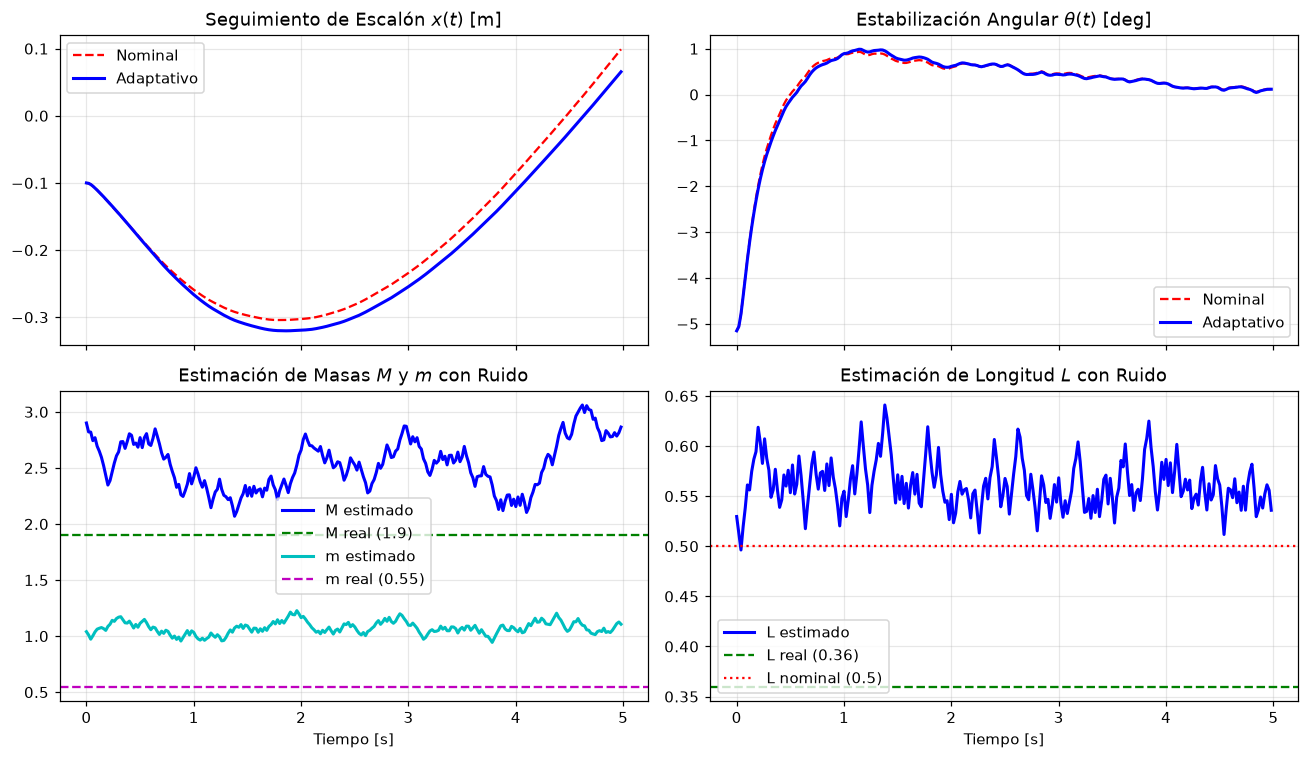

In [17]:
theta_real_p2 = [1.90, 0.55, 0.36, 0.008]
ruido_sensor = [0.002, 0.010, 0.002, 0.015]  # [m, m/s, rad, rad/s]

res_p2 = evaluador.comparar_modos(
    theta_real=theta_real_p2,
    theta_inicial=THETA_NOMINAL,
    estado_inicial=(-0.10, 0.0, -0.09, 0.0),
    pasos=250,
    fn_referencia=referencia_escalon_simple,
    ruido_medicion_std=ruido_sensor,
)

print('=== MÉTRICAS PRUEBA 2 (Planta liviana/corta + ruido de sensores) ===')
for modo, data in res_p2.items():
    m = data['metricas']
    print(
        f"{modo.upper():10s} | Estable: {str(m['estable']):5s} | "
        f"RMSE x: {m['rmse_x']:.4f} m | RMSE theta: {m['rmse_theta_deg']:.2f} deg | "
        f"Energía u: {m['energia_u']:.1f}"
    )

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
d2_adapt = res_p2['adaptativo']
d2_nom = res_p2['nominal']


axes[0, 0].plot(d2_nom['t'], d2_nom['estados_reales'][:, 0], 'r--', label='Nominal')
axes[0, 0].plot(d2_adapt['t'], d2_adapt['estados_reales'][:, 0], 'b-', lw=2, label='Adaptativo')
axes[0, 0].set_title('Seguimiento de Escalón $x(t)$ [m]')
axes[0, 0].legend()

axes[0, 1].plot(d2_nom['t'], np.degrees(d2_nom['estados_reales'][:, 2]), 'r--', label='Nominal')
axes[0, 1].plot(d2_adapt['t'], np.degrees(d2_adapt['estados_reales'][:, 2]), 'b-', lw=2, label='Adaptativo')
axes[0, 1].set_title(r'Estabilización Angular $\theta(t)$ [deg]')
axes[0, 1].legend()

axes[1, 0].plot(d2_adapt['t'], d2_adapt['theta_estimado'][:, 0], 'b-', lw=2, label='M estimado')
axes[1, 0].axhline(theta_real_p2[0], color='g', ls='--', label=f'M real ({theta_real_p2[0]})')
axes[1, 0].plot(d2_adapt['t'], d2_adapt['theta_estimado'][:, 1], 'c-', lw=2, label='m estimado')
axes[1, 0].axhline(theta_real_p2[1], color='m', ls='--', label=f'm real ({theta_real_p2[1]})')
axes[1, 0].set_title('Estimación de Masas $M$ y $m$ con Ruido')
axes[1, 0].set_xlabel('Tiempo [s]')
axes[1, 0].legend()

axes[1, 1].plot(d2_adapt['t'], d2_adapt['theta_estimado'][:, 2], 'b-', lw=2, label='L estimado')
axes[1, 1].axhline(theta_real_p2[2], color='g', ls='--', label=f'L real ({theta_real_p2[2]})')
axes[1, 1].axhline(THETA_NOMINAL[2], color='r', ls=':', label=f'L nominal ({THETA_NOMINAL[2]})')
axes[1, 1].set_title('Estimación de Longitud $L$ con Ruido')
axes[1, 1].set_xlabel('Tiempo [s]')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

## 4. Prueba 3: Batería de Generalización sobre 10 Plantas Aleatorias

In [15]:
rng_test = np.random.default_rng(2026)
resultados_bateria = []

print(f"{'#':>2s} | {'Planta Real [M, m, L]':22s} | {'RMSE x Nom':>10s} | {'RMSE x Adap':>11s} | {'Err% M':>6s} | {'Err% m':>6s} | {'Err% L':>6s}")
print('-' * 82)

for idx in range(10):
    planta = [
        float(rng_test.uniform(1.8, 5.2)),
        float(rng_test.uniform(0.5, 1.8)),
        float(rng_test.uniform(0.35, 0.85)),
        float(rng_test.uniform(0.006, 0.025)),
    ]
    comp = evaluador.comparar_modos(theta_real=planta, pasos=250)
    m_n = comp['nominal']['metricas']
    m_a = comp['adaptativo']['metricas']
    resultados_bateria.append((m_n, m_a))
    planta_str = f'[{planta[0]:.2f}, {planta[1]:.2f}, {planta[2]:.2f}]'
    print(
        f"{idx+1:2d} | {planta_str:22s} | {m_n['rmse_x']:10.4f} | {m_a['rmse_x']:11.4f} | "
        f"{m_a['err_rel_pct_M']:5.1f}% | {m_a['err_rel_pct_m']:5.1f}% | {m_a['err_rel_pct_L']:5.1f}%"
    )

rmse_x_nom_med = np.mean([r[0]['rmse_x'] for r in resultados_bateria])
rmse_x_adp_med = np.mean([r[1]['rmse_x'] for r in resultados_bateria])
mejora_pct = 100.0 * (rmse_x_nom_med - rmse_x_adp_med) / rmse_x_nom_med
print('-' * 82)
print(f'RMSE x promedio -> Nominal: {rmse_x_nom_med:.4f} m | Adaptativo: {rmse_x_adp_med:.4f} m (Mejora: {mejora_pct:+.1f}%)')

 # | Planta Real [M, m, L]  | RMSE x Nom | RMSE x Adap | Err% M | Err% m | Err% L
----------------------------------------------------------------------------------
 1 | [2.41, 1.33, 0.58]     |     0.6316 |      0.6380 |  22.8% |  15.4% |   4.7%
 2 | [3.01, 1.53, 0.80]     |     0.6604 |      0.6726 |   9.8% |  24.2% |  29.9%
 3 | [4.02, 0.89, 0.83]     |     0.6807 |      0.6987 |   8.2% |  33.4% |  31.0%
 4 | [3.96, 1.48, 0.61]     |     0.6989 |      0.7208 |   3.0% |  18.5% |   4.5%
 5 | [3.32, 0.94, 0.49]     |     0.6453 |      0.6520 |  11.6% |  19.5% |  14.1%
 6 | [3.59, 1.06, 0.68]     |     0.6631 |      0.6758 |   6.9% |   9.7% |  17.3%
 7 | [3.32, 0.97, 0.45]     |     0.6454 |      0.6526 |  11.0% |  16.4% |  24.3%
 8 | [3.28, 0.89, 0.45]     |     0.6419 |      0.6465 |  12.4% |  24.3% |  22.8%
 9 | [4.51, 1.29, 0.52]     |     0.7199 |      0.7474 |   8.9% |   5.8% |  12.4%
10 | [3.72, 1.06, 0.80]     |     0.6724 |      0.6880 |   4.7% |  10.5% |  28.8%
---------------

## 5. Animación del Carrito Andando (Prueba 1 — MPC Adaptativo)

Visualizamos el carro sobre el riel, la barra del péndulo con su masa en el extremo, la referencia móvil $x_{ref}(t)$ (triángulo verde) y los valores estimados en tiempo real.

In [16]:
def animar_carrito(resultado_sim: dict, salto_frames: int = 2, intervalo_ms: int = 40) -> HTML:
    t = resultado_sim['t'][::salto_frames]
    estados = resultado_sim['estados_reales'][::salto_frames]
    refs = resultado_sim['referencias'][::salto_frames]
    fuerzas = resultado_sim['acciones_u'][::salto_frames]
    thetas_est = resultado_sim['theta_estimado'][::salto_frames]
    M_r, m_r, L_r, _ = resultado_sim['theta_real']

    fig, ax = plt.subplots(figsize=(10, 4.6))
    x_max_vista = max(1.4, float(np.max(np.abs(estados[:, 0]))) + 0.6)
    ax.set_xlim(-x_max_vista, x_max_vista)
    ax.set_ylim(-0.35, L_r + 0.55)
    ax.set_aspect('equal')
    ax.set_xlabel('Posición sobre el riel $x$ [m]')
    ax.set_ylabel('Altura $y$ [m]')
    ax.set_title('Simulación en Lazo Cerrado: Carro-Péndulo con MPC Adaptativo (AG)')

    # Riel
    ax.axhline(0.0, color='#444444', lw=3, zorder=1)

    # Geometría del carro y ruedas
    ancho_carro, alto_carro = 0.34, 0.16
    radio_rueda = 0.04
    y_carro = radio_rueda * 2.0

    carro_patch = patches.FancyBboxPatch(
        (-ancho_carro / 2, y_carro),
        ancho_carro,
        alto_carro,
        boxstyle='round,pad=0.01,rounding_size=0.02',
        facecolor='#1f77b4',
        edgecolor='#0d3b66',
        lw=1.8,
        zorder=3,
    )
    ax.add_patch(carro_patch)

    rueda_izq = patches.Circle((0, radio_rueda), radio_rueda, facecolor='#222222', zorder=4)
    rueda_der = patches.Circle((0, radio_rueda), radio_rueda, facecolor='#222222', zorder=4)
    ax.add_patch(rueda_izq)
    ax.add_patch(rueda_der)

    # Péndulo y masa puntual
    linea_pendulo, = ax.plot([], [], color='#d95f02', lw=4.0, solid_capstyle='round', zorder=5)
    pivote, = ax.plot([], [], 'ko', markersize=6, zorder=6)
    masa_pendulo = patches.Circle((0, 0), 0.055, facecolor='#e7298a', edgecolor='#67001f', lw=1.5, zorder=6)
    ax.add_patch(masa_pendulo)

    # Marcador de referencia x_ref
    marcador_ref, = ax.plot([], [], marker='^', markersize=11, color='#2ca02c', label='Referencia $x_{ref}$', zorder=7)

    # Flecha de fuerza aplicada
    flecha_u = ax.annotate(
        '', xy=(0, y_carro + alto_carro / 2), xytext=(0, y_carro + alto_carro / 2),
        arrowprops=dict(arrowstyle='->', color='#d62728', lw=2.2),
        zorder=7,
    )

    # Panel informativo en tiempo real
    texto_info = ax.text(
        0.02, 0.96, '', transform=ax.transAxes, va='top', ha='left',
        fontsize=9.5, family='monospace',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.88, edgecolor='#cccccc'),
    )
    ax.legend(loc='upper right')

    def init():
        linea_pendulo.set_data([], [])
        pivote.set_data([], [])
        marcador_ref.set_data([], [])
        texto_info.set_text('')
        return carro_patch, rueda_izq, rueda_der, linea_pendulo, pivote, masa_pendulo, marcador_ref, texto_info

    def update(frame):
        x, _, theta, _ = estados[frame]
        x_ref = refs[frame, 0]
        u = fuerzas[frame]
        M_e, m_e, L_e, _ = thetas_est[frame]

        carro_patch.set_x(x - ancho_carro / 2)
        rueda_izq.center = (x - ancho_carro * 0.30, radio_rueda)
        rueda_der.center = (x + ancho_carro * 0.30, radio_rueda)

        px0 = x
        py0 = y_carro + alto_carro
        px1 = px0 + L_r * np.sin(theta)
        py1 = py0 + L_r * np.cos(theta)

        linea_pendulo.set_data([px0, px1], [py0, py1])
        pivote.set_data([px0], [py0])
        masa_pendulo.center = (px1, py1)
        marcador_ref.set_data([x_ref], [-0.07])

        # Escalar flecha de fuerza
        escala_f = 0.012
        y_f = y_carro + alto_carro / 2
        if abs(u) > 0.3:
            x_inicio = x - np.sign(u) * (ancho_carro / 2 + 0.03)
            flecha_u.xy = (x_inicio + u * escala_f, y_f)
            flecha_u.set_position((x_inicio, y_f))
        else:
            flecha_u.xy = (x, y_f)
            flecha_u.set_position((x, y_f))

        texto_info.set_text(
            f't = {t[frame]:4.2f} s | x = {x:+.2f} m (ref: {x_ref:+.2f}) | theta = {np.degrees(theta):+5.1f} deg | u = {u:+5.1f} N\n'
            f'Est: M={M_e:.2f} kg, m={m_e:.2f} kg, L={L_e:.2f} m  ||  Real: M={M_r:.2f} kg, m={m_r:.2f} kg, L={L_r:.2f} m'
        )
        return carro_patch, rueda_izq, rueda_der, linea_pendulo, pivote, masa_pendulo, marcador_ref, texto_info

    anim = animation.FuncAnimation(
        fig, update, frames=len(t), init_func=init, interval=intervalo_ms, blit=False
    )
    plt.close(fig)
    return HTML(anim.to_jshtml())

animar_carrito(res_p1['adaptativo'], salto_frames=3, intervalo_ms=40)